# Load the Dataset

In [4]:
import numpy as np
%matplotlib inline

data = np.genfromtxt('Data_Cortex_Nuclear.csv',delimiter=',',
                     skip_header=1,usecols=range(1,78),filling_values=0)
classes = np.genfromtxt('Data_Cortex_Nuclear.csv',delimiter=',',
                        skip_header=1,usecols=range(78,81),dtype=None)

Separate target and background (control) datasets:
* Target = mice that received shock therapy. Some have Down Syndrome, others don't, but it is assumed this label is not known *a priori*
* Background = mice that have not been stimulated by shock therapy, and do not have Down Syndrome. 

In [5]:
target_idx_A = np.where((classes[:,-1]=='S/C') & (classes[:,-2]=='Saline') & (classes[:,-3]=='Control'))[0]
target_idx_B = np.where((classes[:,-1]=='S/C') & (classes[:,-2]=='Saline') & (classes[:,-3]=='Ts65Dn'))[0]

labels = len(target_idx_A)*[0] + len(target_idx_B)*[1]
target_idx = np.concatenate((target_idx_A,target_idx_B))                                                                          

target = data[target_idx]

background_idx = np.where((classes[:,-1]=='C/S') & (classes[:,-2]=='Saline') & (classes[:,-3]=='Control'))
background = data[background_idx]

### Run alpha=2 as selected by the authors (not shown in the report)

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/matplotlib/collections.py:205: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


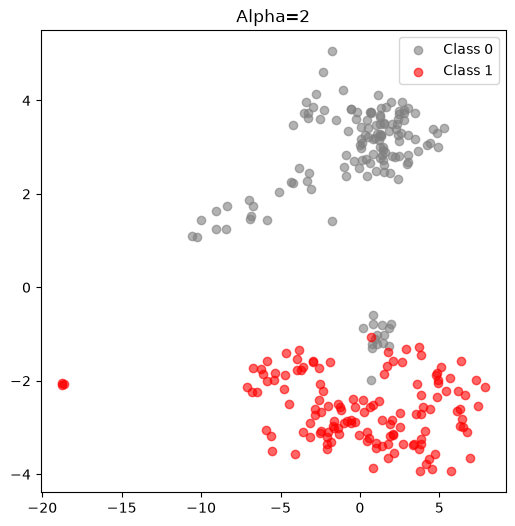

In [6]:
import os,sys,inspect
from contrastive import CPCA

mdl = CPCA()
projected_data = mdl.fit_transform(target, background, plot=True, active_labels=labels, alpha_selection='manual', alpha_value=2, colors=['gray', 'r'])

## Experimenting with different alphas via auto-selection from a broad range

/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/matplotlib/cbook.py:1810: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/matplotlib/collections.py:205: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


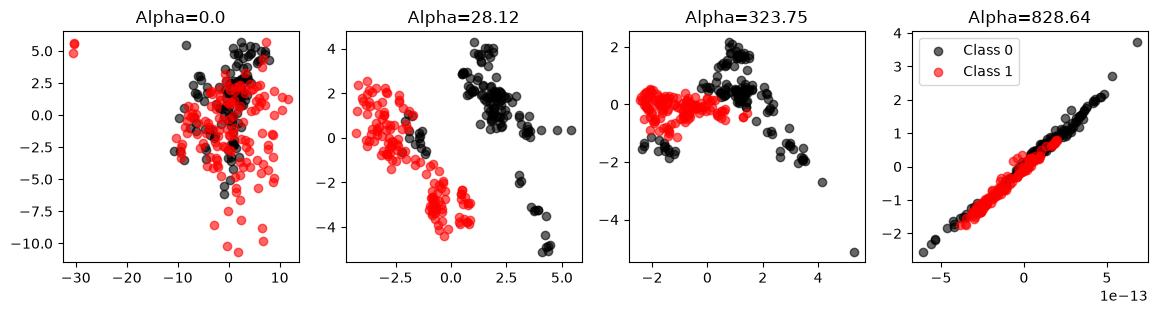

In [37]:
projected_data = mdl.fit_transform(target, background, plot=True, active_labels=labels, 
                                   n_alphas=50, max_log_alpha=3, n_alphas_to_return=4)

## Running a standard PCA (standardised and not)

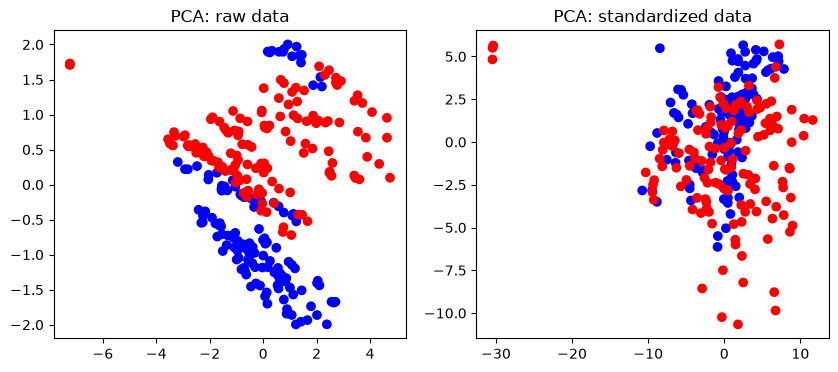

In [5]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

#1 PCA on target data as is
pca = PCA(n_components=2)
p1 = pca.fit_transform(target)

#2 PCA after standardizing each protein
p2 = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(target))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].scatter(p1[:, 0], p1[:, 1], c=labels, cmap='bwr')
ax[0].set_title('PCA: raw data')
ax[1].scatter(p2[:, 0], p2[:, 1], c=labels, cmap='bwr')
ax[1].set_title('PCA: standardized data')

plt.show()
